<a href="https://colab.research.google.com/github/leejsya/AI_Study/blob/main/HAR/HAR_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#### Library Import

In [ ]:
import random
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, f1_score, confusion_matrix

from tqdm.auto import tqdm

#### 시드 고정

In [ ]:
SEED = 42

In [ ]:
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

#### Device 설정

In [ ]:
device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)

In [ ]:
SIGNAL_NAMES = [
    "body_acc_x",
    "body_acc_y",
    "body_acc_z",

    "body_gyro_x",
    "body_gyro_y",
    "body_gyro_z",

    "total_acc_x",
    "total_acc_y",
    "total_acc_z"
]


CLASS_NAMES = [
    "WALKING",
    "WALKING_UPSTAIRS",
    "WALKING_DOWNSTAIRS",
    "SITTING",
    "STANDING",
    "LAYING"
]

#### 데이터셋 로드

In [ ]:
# signal 데이터를 load하는 function
def load_signals(split):
    signals = [
        np.loadtxt(f"./data/{split}/Inertial_Signals/{names}_{split}.txt", dtype=np.float32) for names in SIGNAL_NAMES
    ]
    return np.stack(signals, axis=-1)

# label 데이터를 load하는 function
def load_labels(split):
    labels = np.loadtxt(f"./data/{split}/y_{split}.txt", dtype=np.int64)
    # 1 ~ 6 -> 0 ~ 5
    return labels - 1

In [ ]:
X_train_full = load_signals("train")
X_test = load_signals("test")

y_train_full = load_labels("train")
y_test = load_labels("test")

In [ ]:
print(f"X_train_full: {X_train_full.shape}")
print(f"X_test: {X_test.shape}")
print()
print(f"y_train_full: {y_train_full.shape}")
print(f"y_test: {y_test.shape}")

X_train_full: (7352, 128, 9)
X_test: (2947, 128, 9)

y_train_full: (7352,)
y_test: (2947,)


#### train/val split

In [ ]:
# train/val -> 0.8:0.2, stratify 적용
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full,
    y_train_full,
    test_size=0.2,
    stratify=y_train_full,
    random_state=SEED,
)

#### 샘플 분석

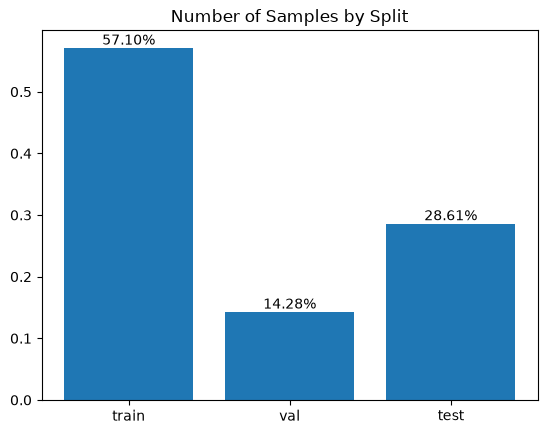

In [ ]:
n_samples = len(y_train) + len(y_val) + len(y_test)
train_prop = len(y_train) / n_samples
val_prop = len(y_val) / n_samples
test_prop = len(y_test) / n_samples
bar1 = plt.bar(['train', 'val', 'test'], [train_prop, val_prop, test_prop])
plt.bar_label(
    bar1,
    labels=[f"{train_prop*100:.2f}%", f"{val_prop*100:.2f}%", f"{test_prop*100:.2f}%"]
)
plt.title("Number of Samples by Split")
plt.show()

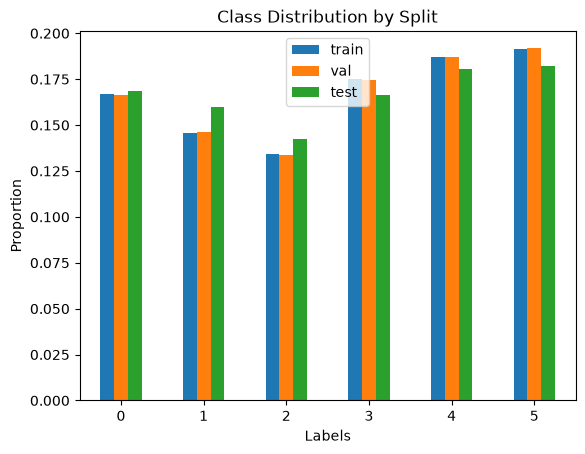

In [ ]:
# stratify가 잘 적용되었는지 split에 따른 클래스 분포 확인
import pandas as pd
labels_dict = {
    'y_train': y_train,
    'y_val': y_val,
    'y_test': y_test,
}
prop_dict = {}
for split in ['train', 'val', 'test']:
    uniques, counts = np.unique(labels_dict[f"y_{split}"], return_counts=True)
    prop_dict[split] = counts/counts.sum()

prop_df = pd.DataFrame(prop_dict)
prop_df.plot.bar(rot=0)
plt.xlabel("Labels")
plt.ylabel("Proportion")
plt.title("Class Distribution by Split")
plt.show()

#### Standardization

In [ ]:
scaler = StandardScaler()
# 채널 수
n_channels = X_train.shape[-1]

# StandardScaler는 2차원 배열을 받음
# 따라서 X_train을 2차원으로 reshape한 형태를 객체로 저장
X_train_2d = X_train.reshape(-1, n_channels)

# scaler.fit()
scaler.fit(X_train_2d)

StandardScaler()

In [ ]:
def standardize(X, scaler):
    # 원본 shape 상태를 백업
    original_shape = X.shape

    # scaler fit할 때와 동일하게 2차원으로 reshape
    X_2d = X.reshape(-1, original_shape[-1])
    # scaler 적용
    X_scaled = scaler.transform(X_2d)
    # 원본 shape으로 복원
    X_scaled = X_scaled.reshape(original_shape)

    return X_scaled.astype(np.float32)


In [ ]:
X_train = standardize(X_train, scaler)
X_val = standardize(X_val, scaler)
X_test = standardize(X_test, scaler)

In [ ]:
X_train.shape

(5881, 128, 9)

#### Dataset

In [ ]:
class HARDataset(Dataset):
    def __init__(self, X, y):
        self.X = X
        self.y = y

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        X_tensor = torch.tensor(self.X[idx], dtype=torch.float32)
        y_tensor = torch.tensor(self.y[idx], dtype=torch.int64)

        return X_tensor, y_tensor

train_dataset = HARDataset(X_train, y_train)
val_dataset = HARDataset(X_val, y_val)
test_dataset = HARDataset(X_test, y_test)

In [ ]:
# 샘플 1개 shape 확인용
train_dataset[0][0].shape

torch.Size([128, 9])

#### DataLoader

In [ ]:
train_dataloader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True,
)
val_dataloader = DataLoader(
    val_dataset,
    batch_size=64,
)
test_dataloader = DataLoader(
    test_dataset,
    batch_size=64,
)

#### Model

In [ ]:
class HARModel(nn.Module):
    def __init__(self):
        super().__init__()
        # Conv1d는 (batch, channel, length) 형태를 받음
        self.conv1 = nn.Conv1d(
            in_channels=9,
            out_channels=64,
            kernel_size=5,
            padding='same'
        )
        self.relu = nn.ReLU()
        self.bn1 = nn.BatchNorm1d(num_features=64)
        self.maxpool = nn.MaxPool1d(kernel_size=2)
        self.dropout = nn.Dropout(0.3)
        self.conv2 = nn.Conv1d(
            in_channels=64,
            out_channels=128,
            kernel_size=5,
            padding="same",
        )
        self.bn2 = nn.BatchNorm1d(num_features=128)

        # LSTM은 (batch, length, channel) 형태를 받음
        self.lstm = nn.LSTM(
            input_size=128,
            hidden_size=128,
            batch_first=True,
        )
        self.linear1 = nn.Linear(
            in_features=128,
            out_features=64,
        )
        self.linear2 = nn.Linear(
            in_features=64,
            out_features=6,
        )
        self.softmax = nn.Softmax()

    def forward(self, x):
        # (batch, length, channel) -> (batch, channel, length)
        x.transpose_(1, 2)
        x = self.conv1(x)
        x = self.relu(x)
        x = self.bn1(x)
        x = self.maxpool(x)
        x = self.dropout(x)

        x = self.conv2(x)
        x = self.relu(x)
        x = self.bn2(x)
        x = self.maxpool(x)
        x = self.dropout(x)

        # (batch, channel, length) -> (batch, length, channel)
        x.transpose_(1, 2)
        x, _ = self.lstm(x)
        x = x[:, -1, :]
        x = self.dropout(x)

        x = self.linear1(x)
        x = self.relu(x)
        x = self.dropout(x)

        x = self.linear2(x)

        return x

#### Evaluation function

In [ ]:
def evaluate(model, criterion):
    model.eval()
    losses = []
    true_labels = []
    pred_labels = []

    with torch.no_grad():
        for batch in val_dataloader:
            signals, labels = batch[0].to(device), batch[1].to(device)

            logits = model(signals)
            loss = criterion(logits, labels)
            losses.append(loss.item())

            probs = torch.softmax(logits, dim=1)
            preds = torch.argmax(probs, dim=1)
            # sklearn의 accuracy_score는 cpu에서만 동작
            pred_labels.extend(preds.cpu())
            true_labels.extend(labels.cpu())

    acc = accuracy_score(true_labels, pred_labels)
    avg_loss = np.mean(losses)

    return avg_loss, acc, true_labels, pred_labels


#### Training function

In [ ]:
def training(dataloader, model, criterion, optimizer, epochs, min_loss, train_history, val_history):
    with tqdm(total=epochs*len(dataloader), desc="Training", dynamic_ncols=True) as pbar:

        for epoch in range(epochs):
            losses = []
            true_labels = []
            pred_labels = []
            model.train()

            for batch in dataloader:
                signals, labels = batch[0].to(device), batch[1].to(device)

                logits = model(signals)
                loss = criterion(logits, labels)

                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

                losses.append(loss.item())
                probs = torch.softmax(logits, dim=1)
                preds = torch.argmax(probs, dim=1)
                # sklearn의 accuracy_score는 cpu에서만 동작하고 np 배열
                pred_labels.extend(preds.cpu())
                true_labels.extend(labels.cpu())

                pbar.update(1)

            train_loss = np.mean(losses)
            train_acc = accuracy_score(true_labels, pred_labels)
            val_loss, val_acc, _, _ = evaluate(model, criterion)

            train_history['loss'].append(train_loss)
            train_history['acc'].append(train_acc)
            val_history['loss'].append(val_loss)
            val_history['acc'].append(val_acc)

            pbar.set_postfix({
                "Epoch": f"({epoch+1}/{epochs})"
            })

            if min_loss >= val_loss:
                min_loss = val_loss
                torch.save(model.state_dict(), 'state_dict/model.pt')

    return min_loss, train_history, val_history


#### Set up & Training

In [ ]:
min_loss = float('inf')
train_history = {
    "loss": [],
    "acc": [],
}
val_history = {
    "loss": [],
    "acc": [],
}

model = HARModel().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3)

min_loss, train_history, val_history = training(
    dataloader=train_dataloader,
    model=model,
    criterion=criterion,
    optimizer=optimizer,
    epochs=50,
    min_loss=min_loss,
    train_history=train_history,
    val_history=val_history,
)

Training:   0%|          | 0/4600 [00:00<?, ?it/s]

#### Evaluation

In [ ]:
def cal_ema(history):
    ema_list = []
    alpha = 0.3

    for i, value in enumerate(history):
        if i == 0:
            ema_value = value
        else:
            ema_value = alpha * value + (1 - alpha) * ema_value
        ema_list.append(ema_value)
    return ema_list

In [ ]:
train_loss_ema = cal_ema(train_history["loss"])
train_acc_ema = cal_ema(train_history["acc"])
val_loss_ema = cal_ema(val_history["loss"])
val_acc_ema = cal_ema(val_history["acc"])

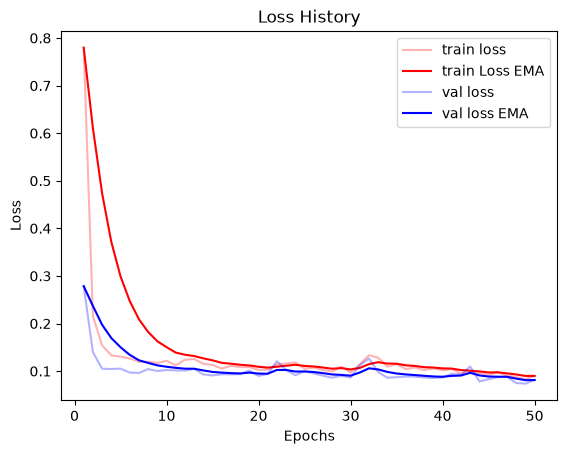

In [ ]:
plt.plot(range(1, 51), train_history['loss'], 'r', label="train loss", alpha=0.3)
plt.plot(range(1, 51), train_loss_ema, 'r', label="train Loss EMA")
plt.plot(range(1, 51), val_history['loss'], 'b', label="val loss", alpha=0.3)
plt.plot(range(1, 51), val_loss_ema, 'b', label="val loss EMA")
plt.title("Loss History")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

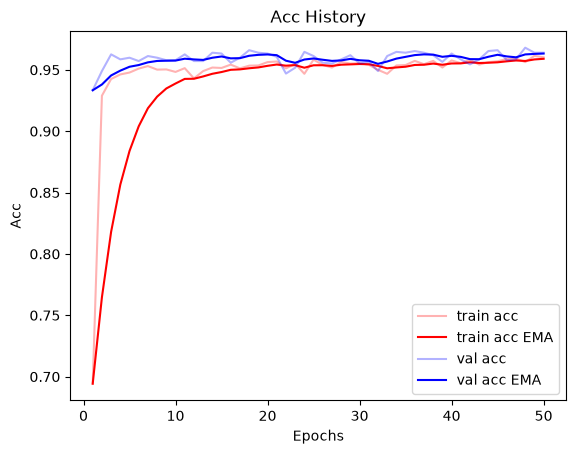

In [ ]:
plt.plot(range(1, 51), train_history['acc'], 'r', label="train acc", alpha=0.3)
plt.plot(range(1, 51), train_acc_ema, 'r', label="train acc EMA")
plt.plot(range(1, 51), val_history['acc'], 'b', label="val acc", alpha=0.3)
plt.plot(range(1, 51), val_acc_ema, 'b', label="val acc EMA")
plt.title("Acc History")
plt.xlabel("Epochs")
plt.ylabel("Acc")
plt.legend()
plt.show()

#### Performance

In [ ]:
best_model = HARModel().to(device)
best_model.load_state_dict(torch.load('state_dict/model.pt', map_location=device))
test_loss, test_acc, test_labels, test_preds = evaluate(
    model=best_model,
    criterion=criterion,
)
print(f"test loss: {test_loss:.4f}, test acc: {test_acc:.4f}")

test loss: 0.0735, test acc: 0.9640


In [ ]:
report = classification_report(
    test_labels, test_preds,
    output_dict=True
)
print(classification_report(test_labels, test_preds))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00       245
           1       1.00      1.00      1.00       215
           2       1.00      1.00      1.00       197
           3       0.86      0.95      0.90       257
           4       0.94      0.86      0.90       275
           5       1.00      1.00      1.00       282

    accuracy                           0.96      1471
   macro avg       0.97      0.97      0.97      1471
weighted avg       0.97      0.96      0.96      1471



In [ ]:
weighted_f1 = f1_score(test_labels, test_preds, average="weighted", zero_division=0)
print(weighted_f1)

0.9639478064261982


In [ ]:
cm = confusion_matrix(test_labels, test_preds)

cm_normalized = (cm.astype(np.float32) / np.max(cm.sum(axis=1, keepdims=True), 1))

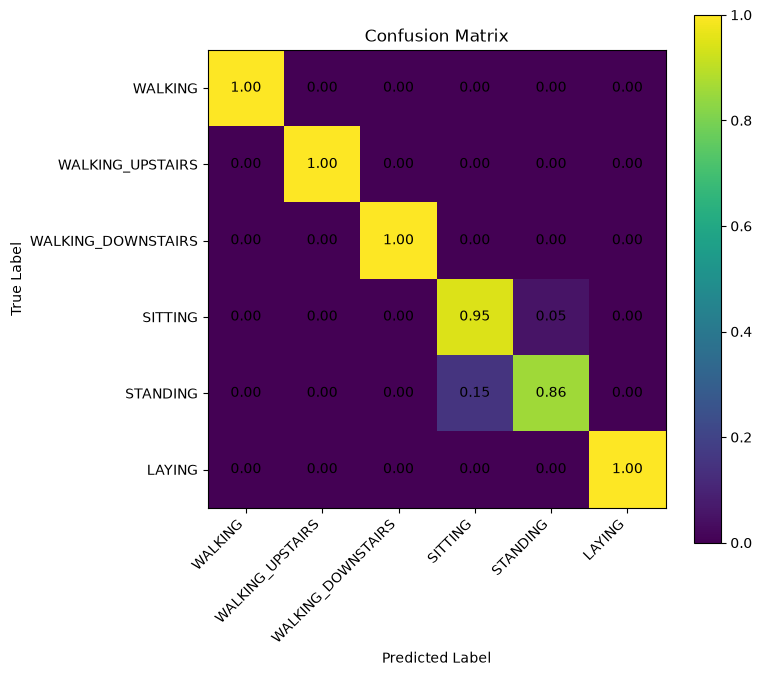

In [ ]:
plt.figure(figsize=(8,7))
plt.imshow(cm_normalized)
plt.colorbar()
plt.xticks(
    np.arange(len(CLASS_NAMES)),
    CLASS_NAMES,
    rotation=45,
    ha="right",
)
plt.yticks(
    np.arange(len(CLASS_NAMES)),
    CLASS_NAMES,
)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")
for i in range(len(CLASS_NAMES)):
    for j in range(len(CLASS_NAMES)):
        plt.text(j, i, f"{cm_normalized[i, j]:.2f}", ha="center", va="center")
plt.tight_layout()
plt.show()